# Comparação dos modelos InsightFace
Nesse notebook eu testo 5 pacotes do InsightFace (`buffalo_l`, `buffalo_m`, `buffalo_s`, `buffalo_sc` e `antelopev2`) nas 6 fotos da sala de aula e em 5 reduções de resolução (80%, 60%, 40%, 20% e 10%, sempre comparando com o original de 100%).

A ideia aqui é ver na prática o quanto o score de similaridade de cosseno e os acertos vão caindo conforme a imagem diminui de tamanho.
Os dados em CSV/JSON ficam salvos na pasta `dados` e os gráficos vão automaticamente para `graficos`.

Observação sobre o banco: as fotos `felipe2` e `felipeFullsta` são da mesma pessoa, então eu junto as duas na identidade `felipe` ficando com a maior similaridade entre elas. Na parte de inferência, eu não mudo nada do InsightFace — uso o embedding padrão (`rosto.embedding`) e aplico apenas o pareamento Húngaro 1-para-1 para não repetir o mesmo nome em dois rostos da mesma foto.

In [1]:
# Imports
# Chamando as libs padrões do Python para mexer com arquivos, pastas, CSV, JSON, tempo e hash SHA-256
import csv
import hashlib
import importlib.metadata
import shutil
import time
import json
import os
from pathlib import Path

# Desativa o aviso de atualização do albumentations para não encher o terminal de warning
os.environ.setdefault("NO_ALBUMENTATIONS_UPDATE", "1")

# Bibliotecas principais de visão computacional, matrizes, ONNX Runtime, InsightFace e otimização
import cv2
import matplotlib
import numpy as np
import onnxruntime as ort
from insightface.app import FaceAnalysis
# linear_sum_assignment implementa o Algoritmo Húngaro, que eu uso no pareamento 1-para-1
from scipy.optimize import linear_sum_assignment

# Uso o backend Agg para gerar e salvar os gráficos direto em PNG sem abrir janela na tela
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# --- Parâmetros principais do experimento ---

# Escalas lineares que eu vou testar: 100% é a foto original, e de 80% até 10% são as versões reduzidas
escalasPercentuais = (100, 80, 60, 40, 20, 10)

# Threshold (limiar) de similaridade de cosseno para dizer se reconheci a pessoa ou se é "Desconhecido"
# No ArcFace (512 dimensões), 0.30 é um valor calibrado para pegar rostos mais distantes sem gerar falso positivo
limiarReconhecimento = 0.30

# Diferença mínima que o 1º candidato precisa ter sobre o 2º candidato no mesmo rosto
# Se dois alunos ficarem com score muito grudado (diferença menor que 0.05), eu prefiro marcar como Desconhecido
margemMinimaCandidato = 0.05

# IoU (sobreposição) mínimo entre a caixa que o detector achou e a caixa do meu gabarito (anotacoesSalas.json)
# Se a sobreposição for menor que 0.30, eu considero que aquele rosto não foi detectado
sobreposicaoMinima = 0.30

# Extensões de imagem aceitas nas pastas imagensSala/ e rostos/
extensoesImagens = {".jpg", ".jpeg", ".png"}

# Os 4 estados possíveis para cada pessoa esperada nas fotos da sala
estadosReconhecimento = ("correto", "desconhecido", 'nomeIncorreto', 'naoDetectado')

# Colunas que vão ser gravadas nos arquivos CSV detalhados (uma linha para cada rosto em cada escala)
camposDetalhes = (
    "sala", 'escalaPercentual', "largura", "altura", 'nomeEsperado', 'nomeReconhecido',
    'melhorCandidato', 'similaridadeCandidato', 'similaridadeEsperada', 'confiancaDetector',
    'sobreposicao', "estado",
)

# Os 5 pacotes ONNX do InsightFace que eu quero comparar e a cor fixa de cada um nos gráficos
modelosDisponiveis = ("buffalo_l", "buffalo_m", "buffalo_s", "buffalo_sc", "antelopev2")
coresModelos = ("#007f75", "#4b78b8", "#bc5b25", "#9d4a90", "#5c7840")

# Configuração
Aqui é onde eu escolho quais pacotes do InsightFace vão rodar, onde ficam salvos os modelos `.onnx` e confiro se o notebook achou a pasta `experimentoModelos` certinha.

In [2]:
# Lista de modelos que vão ser executados (por padrão roda todos os 5)
modelosSelecionados = list(modelosDisponiveis)

# Pasta padrão do InsightFace no usuário (C:\Users\Usuário\.insightface) onde ficam os arquivos .onnx
pastaModelos = Path.home() / ".insightface"

# Se ficar True, o código salva as 30 imagens reduzidas (80% até 10%) em PNG dentro de imagensSala/reduzidas/
salvarImagensReduzidas = True

# Procura automaticamente a pasta experimentoModelos testando caminhos possíveis
# Eu confirmo que é a pasta certa verificando se o arquivo anotacoesSalas.json está lá dentro
pastaAtual = Path.cwd()
pastasCandidatas = [
    pastaAtual,
    pastaAtual / "experimentoModelos",
    pastaAtual / "FaceRecognition" / "experimentoModelos",
    pastaAtual / "ModelosRedesNeurais" / "FaceRecognition" / "experimentoModelos",
]
pastaExperimento = next(
    (pasta for pasta in pastasCandidatas if (pasta / "anotacoesSalas.json").is_file()),
    None,
)
if pastaExperimento is None:
    raise FileNotFoundError("Abra este notebook na pasta experimentoModelos.")

print(f"Pasta do experimento: {pastaExperimento}")
print(f"Modelos selecionados: {', '.join(modelosSelecionados)}")

Pasta do experimento: c:\Users\Usuário\Desktop\pesquisa\ModelosRedesNeurais\FaceRecognition\experimentoModelos
Modelos selecionados: buffalo_l, buffalo_m, buffalo_s, buffalo_sc, antelopev2


# Imagens, referências e inferência
Aqui ficam as funções que realmente fazem o reconhecimento facial funcionar:
- leitura das imagens sem bug de acento no Windows;
- carregamento dos arquivos `.onnx` do InsightFace;
- extração do banco de embeddings das fotos de referência;
- cálculo da similaridade de cosseno (ArcFace);
- pareamento Húngaro 1-para-1 para atribuir os nomes na sala;
- redimensionamento (`cv2.INTER_AREA`) de 100% até 10% e coleta das detecções.

In [3]:
# Mapeia nomes de arquivos que pertencem à mesma pessoa
# Como o Felipe tem duas fotos na pasta rostos/ (felipe2 e felipeFullsta), eu padronizo as duas como "felipe"
def normalizarNomePessoa(nomeReferencia):
    equivalencias = {
        "felipe2": "felipe",
        "felipefullsta": "felipe",
    }
    # casefold() ignora maiúsculas e minúsculas na hora de comparar
    return equivalencias.get(nomeReferencia.casefold(), nomeReferencia)


# Junta as similaridades de múltiplas fotos da mesma pessoa em um único score por indivíduo
# No caso do Felipe, se uma foto deu 0.42 e a outra deu 0.51, eu fico com o maior valor (0.51)
def agruparSimilaridades(similaridadesReferencias):
    similaridadesPessoas = {}
    for nomeReferencia, similaridade in similaridadesReferencias.items():
        nomePessoa = normalizarNomePessoa(nomeReferencia)
        similaridadesPessoas[nomePessoa] = max(
            similaridadesPessoas.get(nomePessoa, -1.0), similaridade
        )
    return similaridadesPessoas


# Lê uma imagem do disco e transforma em matriz BGR do OpenCV
# Eu uso np.fromfile + cv2.imdecode porque o cv2.imread normal quebra no Windows quando o caminho tem acento (tipo "Usuário")
def lerImagem(caminho):
    imagem = cv2.imdecode(np.fromfile(caminho, dtype=np.uint8), cv2.IMREAD_COLOR)
    if imagem is None:
        raise ValueError(f"Imagem inválida: {caminho}")
    return imagem


# Calcula a similaridade de cosseno entre dois vetores (embeddings de 512 dimensões do ArcFace)
# Quanto mais próximo de 1.0, mais parecidos são os rostos; pessoas diferentes costumam ficar perto de 0
def calcularSimilaridadeCosseno(caixaA, caixaB):
    return float(np.dot(caixaA, caixaB) / (np.linalg.norm(caixaA) * np.linalg.norm(caixaB)))


# Corrige um problema de download do InsightFace em alguns pacotes (buffalo_m e antelopev2)
# Quando ele descompacta o .zip, às vezes cria uma pasta duplicada (models/antelopev2/antelopev2/*.onnx)
# Essa função move os arquivos .onnx um nível para cima e apaga a subpasta extra para não dar AssertionError
def normalizarPastaModelo(nome, root):
    subpasta = Path(root) / "models" / nome / nome
    if subpasta.is_dir():
        for arquivoOnnx in subpasta.glob("*.onnx"):
            shutil.move(str(arquivoOnnx), str(subpasta.parent / arquivoOnnx.name))
        subpasta.rmdir()


# Carrega o pacote ONNX escolhido no ONNX Runtime usando a CPU
def carregarModelo(nome, root):
    # Primeiro verifica se a pasta do modelo precisa ser corrigida
    normalizarPastaModelo(nome, root)

    # Configura as threads da CPU no ONNX Runtime para rodar rápido e de forma consistente
    opcoes = ort.SessionOptions()
    opcoes.intra_op_num_threads = 4
    opcoes.inter_op_num_threads = 1

    # Carrego apenas os módulos de detecção (SCRFD) e reconhecimento (ArcFace)
    # Não carrego genderage nem landmarks 2d106/3d68 porque aqui não preciso deles e assim fica bem mais rápido
    try:
        aplicacao = FaceAnalysis(
            name=nome, root=str(root), providers=["CPUExecutionProvider"],
            allowed_modules=["detection", "recognition"], sess_options=opcoes,
        )
    except AssertionError:
        # Se acabou de baixar o .zip agora e criou subpasta duplicada, corrige e tenta carregar de novo
        normalizarPastaModelo(nome, root)
        aplicacao = FaceAnalysis(
            name=nome, root=str(root), providers=["CPUExecutionProvider"],
            allowed_modules=["detection", "recognition"], sess_options=opcoes,
        )

    # ctx_id=-1 força o uso da CPU; det_size=(640, 640) é a resolução interna do detector; det_thresh=0.50 é a confiança mínima
    aplicacao.prepare(ctx_id=-1, det_size=(640, 640), det_thresh=0.50)
    return aplicacao


# Monta o banco de dados vetorial percorrendo todas as fotos individuais da pasta rostos/
def criarBancoRostos(aplicacao, pasta):
    # Criação de um dicionário vazio que vai guardar {nome_da_foto: vetor_de_512_dimensoes}
    bancoRostos = {}
    for caminho in sorted(pasta.iterdir()):
        # Ignora subpastas ou arquivos que não sejam imagem
        if not caminho.is_file() or caminho.suffix.lower() not in extensoesImagens:
            continue

        # Passa a foto de referência no InsightFace para detectar o rosto e extrair o embedding padrão
        rostos = aplicacao.get(lerImagem(caminho))
        if not rostos:
            raise ValueError(f"Nenhum rosto encontrado na referência {caminho.name}")
        if len(rostos) > 1:
            print(f"{caminho.name}: {len(rostos)} rostos. Usando o primeiro, como no notebook.")

        # caminho.stem tira a extensão (.jpg, .png) e fica só com o nome da pessoa
        bancoRostos[caminho.stem] = rostos[0].embedding

    if not bancoRostos:
        raise ValueError("O banco de referências está vazio.")
    return bancoRostos


# Faz a atribuição final dos nomes na sala inteira usando o Algoritmo Húngaro (pareamento 1-para-1)
# O motivo de usar isso é que cada aluno só pode estar sentado em um lugar da foto
# Se eu escolhesse cada rosto isoladamente, em resoluções baixas dois rostos borrados poderiam receber o mesmo nome
def atribuirIdentidadesSala(rostos):
    if not rostos:
        return

    # Lista ordenada das 12 pessoas do banco para montar as colunas da matriz
    nomesPessoas = sorted(rostos[0]["similaridades"])

    # Monta a matriz de similaridades onde cada linha é um rosto detectado na sala e cada coluna é uma pessoa do banco
    matrizSimilaridades = np.array([
        [rosto["similaridades"][nome] for nome in nomesPessoas]
        for rosto in rostos
    ])

    # O Algoritmo Húngaro encontra a combinação 1-para-1 que maximiza a soma total dos scores na foto inteira
    linhas, colunas = linear_sum_assignment(matrizSimilaridades, maximize=True)
    atribuicoes = {int(linha): nomesPessoas[int(coluna)] for linha, coluna in zip(linhas, colunas)}

    # Agora percorro cada rosto detectado para conferir se o pareamento passa nas regras de segurança
    for indiceRosto, rosto in enumerate(rostos):
        # Ordena todos os scores desse rosto do maior para o menor para descobrir quem ficou em 2º lugar
        valoresOrdenados = sorted(rosto["similaridades"].values(), reverse=True)
        segundaMaior = valoresOrdenados[1] if len(valoresOrdenados) > 1 else -1.0

        melhorNome = rosto["melhorCandidato"]
        melhorScore = rosto["similaridadeCandidato"]
        nomeAtribuido = atribuicoes.get(indiceRosto)

        # Só aceito reconhecer a pessoa se passar nas 3 condições ao mesmo tempo:
        # 1) O nome escolhido no pareamento Húngaro é o mesmo que o melhor candidato desse rosto
        # 2) O score é maior ou igual ao limiar (0.30)
        # 3) A vantagem para o 2º colocado é de pelo menos 0.05 (evita chute em rosto muito borrado)
        if (
            nomeAtribuido == melhorNome
            and melhorScore >= limiarReconhecimento
            and (melhorScore - segundaMaior) >= margemMinimaCandidato
        ):
            rosto["nomeReconhecido"] = melhorNome
        else:
            rosto["nomeReconhecido"] = "Desconhecido"


# Executa o teste em lote: lê as 6 fotos da sala, gera as 6 escalas (100% até 10%), detecta os rostos e calcula os scores
def coletarResultados(aplicacao, bancoRostos, pasta, destino=None):
    resultados = {}
    for caminho in sorted(pasta.iterdir()):
        if not caminho.is_file() or caminho.suffix.lower() not in extensoesImagens:
            continue

        # Lê a foto original da sala (100%) e pega altura e largura em pixels
        imagemOriginal = lerImagem(caminho)
        altura, largura = imagemOriginal.shape[:2]
        resultados[caminho.stem] = {}

        # Percorre as 6 escalas (100%, 80%, 60%, 40%, 20% e 10%)
        for escalaPercentual in escalasPercentuais:
            # Calcula a nova largura e altura proporcionais à escala atual
            dimensoes = (round(largura * escalaPercentual / 100), round(altura * escalaPercentual / 100))
            inicio = time.perf_counter()

            # Redimensiona sempre a partir da imagem original (nunca da anterior) para não acumular erro
            # Uso cv2.INTER_AREA porque faz a média dos pixels da área e evita serrilhamento na redução
            imagemSala = imagemOriginal if escalaPercentual == 100 else cv2.resize(imagemOriginal, dimensoes, interpolation=cv2.INTER_AREA)

            # Salva a imagem reduzida em PNG (sem compressão com perda tipo JPEG) para poder inspecionar depois
            if destino is not None and escalaPercentual < 100:
                sucesso, imagemCodificada = cv2.imencode(".png", imagemSala)
                if not sucesso:
                    raise ValueError(f"Erro salvando {caminho.name} a {escalaPercentual}%.")
                imagemCodificada.tofile(destino / f"{caminho.stem}Escala{escalaPercentual:02d}.png")

            # Como a caixa detectada (bbox) vem nas coordenadas da imagem reduzida, eu calculo esse fator
            # para multiplicar [x1, y1, x2, y2] e devolver a caixa para a escala 100% (igual ao anotacoesSalas.json)
            fatoresCoordenadas = np.array([largura / dimensoes[0], altura / dimensoes[1]] * 2)
            rostos = []

            # Percorrendo todos os rostos que o InsightFace encontrou nessa cena
            for rosto in aplicacao.get(imagemSala):
                # Comparo o embedding padrão do rosto com todas as 13 fotos de referência usando similaridade de cosseno
                similaridadesReferencias = {
                    nome: calcularSimilaridadeCosseno(rosto.embedding, referencia)
                    for nome, referencia in bancoRostos.items()
                }
                # Agrupa as 13 referências nas 12 pessoas (juntando felipe2 e felipeFullsta)
                similaridades = agruparSimilaridades(similaridadesReferencias)
                # Descobre quem teve o maior score para esse rosto
                melhorNome = max(similaridades, key=similaridades.get)

                # Guarda todas as informações desse rosto (caixa reescalonada, confiança, scores e melhor candidato)
                rostos.append({
                    'caixa': (rosto.bbox * fatoresCoordenadas).tolist(),
                    'confiancaDetector': float(rosto.det_score),
                    'similaridades': similaridades,
                    'similaridadesReferencias': similaridadesReferencias,
                    'melhorCandidato': melhorNome,
                    'similaridadeCandidato': similaridades[melhorNome],
                    'nomeReconhecido': "Desconhecido",
                })

            # Depois de coletar todos os rostos da foto, aplica o pareamento Húngaro 1-para-1 na sala inteira
            atribuirIdentidadesSala(rostos)
            resultados[caminho.stem][escalaPercentual] = {'dimensoes': dimensoes, 'rostos': rostos, 'tempoSegundos': time.perf_counter() - inicio}

        # Mostra no terminal quantos rostos o modelo detectou em cada escala dessa sala
        print(f"{caminho.stem}: " + " / ".join(str(len(item['rostos'])) for item in resultados[caminho.stem].values()), flush=True)
    return resultados

# Revisão das anotações
Aqui eu ploto as 6 fotos originais desenhando as bounding boxes e os nomes esperados que vêm do `anotacoesSalas.json`.
Isso serve só para conferência visual minha, para garantir que o gabarito está certinho antes de confiar nas métricas.
Felipe usa as referências `felipe2` e `felipeFullsta`. João Pedro e Péricles aparecem apenas nas salas 2 a 5.

In [4]:
# Célula visual para conferir se as caixas e os nomes do anotacoesSalas.json estão certos
from IPython.display import display
from matplotlib.patches import Rectangle

# Lê o arquivo JSON com o gabarito de cada sala (nome do aluno -> [x1, y1, x2, y2])
anotacoesRevisao = json.loads(
    (pastaExperimento / "anotacoesSalas.json").read_text(encoding="utf-8")
)

# Percorre as 6 salas para desenhar os retângulos e nomes sobre cada foto original
for nomeSala, pessoasSala in sorted(anotacoesRevisao.items()):
    # Procura o arquivo de imagem correspondente ao nome da sala
    caminhosSala = [
        caminho for caminho in (pastaExperimento / "imagensSala").iterdir()
        if caminho.is_file() and caminho.stem == nomeSala
        and caminho.suffix.lower() in extensoesImagens
    ]
    if len(caminhosSala) != 1:
        raise ValueError(f"Esperava uma imagem original para {nomeSala}.")

    imagemRevisao = lerImagem(caminhosSala[0])
    figuraRevisao, eixoRevisao = plt.subplots(figsize=(15, 10), layout="constrained")
    # O OpenCV lê em BGR e o Matplotlib exibe em RGB, então eu converto as cores aqui
    eixoRevisao.imshow(cv2.cvtColor(imagemRevisao, cv2.COLOR_BGR2RGB))

    # Desenha um retângulo verde e escreve o nome esperado em cima de cada rosto anotado
    for nomePessoa, coordenadas in pessoasSala.items():
        esquerda, topo, direita, fundo = coordenadas
        eixoRevisao.add_patch(Rectangle(
            (esquerda, topo), direita - esquerda, fundo - topo,
            fill=False, edgecolor="#00caa4", linewidth=2,
        ))
        eixoRevisao.text(
            esquerda, topo - 6, nomePessoa, color="white", fontsize=11,
            fontweight="bold", verticalalignment="bottom",
            bbox={"facecolor": "#153c36", "alpha": .9, "edgecolor": "none", "pad": 3},
        )

    # Ajusta o zoom da figura para focar só na região onde os alunos estão sentados
    caixasRevisao = np.array(list(pessoasSala.values()))
    eixoRevisao.set_xlim(
        max(0, caixasRevisao[:, 0].min() - 70),
        min(imagemRevisao.shape[1], caixasRevisao[:, 2].max() + 70),
    )
    eixoRevisao.set_ylim(
        min(imagemRevisao.shape[0], caixasRevisao[:, 3].max() + 90),
        max(0, caixasRevisao[:, 1].min() - 90),
    )
    eixoRevisao.set_title(
        f"{nomeSala} — conferir {len(pessoasSala)} nomes esperados", fontsize=16,
    )
    eixoRevisao.axis("off")
    display(figuraRevisao)
    plt.close(figuraRevisao)

<Figure size 1500x1000 with 1 Axes>

<Figure size 1500x1000 with 1 Axes>

<Figure size 1500x1000 with 1 Axes>

<Figure size 1500x1000 with 1 Axes>

<Figure size 1500x1000 with 1 Axes>

<Figure size 1500x1000 with 1 Axes>

# Avaliação das identidades e exportação
Aqui eu comparo o que o modelo detectou com o gabarito (`anotacoesSalas.json`).
Eu calculo o IoU entre as caixas para saber qual detecção corresponde a qual aluno, classifico cada rosto em um dos 4 estados (`correto`, `desconhecido`, `nomeIncorreto`, `naoDetectado`), calculo os percentuais finais e salvo tudo em CSV.

In [5]:
# Calcula o IoU (Intersection over Union) entre duas bounding boxes [x1, y1, x2, y2]
# IoU = área da interseção dividida pela área da união; vai de 0 (não encosta) até 1 (encaixe perfeito)
def calcularSobreposicao(caixaA, caixaB):
    largura = max(0, min(caixaA[2], caixaB[2]) - max(caixaA[0], caixaB[0]))
    altura = max(0, min(caixaA[3], caixaB[3]) - max(caixaA[1], caixaB[1]))
    intersecao = largura * altura
    areaA = (caixaA[2] - caixaA[0]) * (caixaA[3] - caixaA[1])
    areaB = (caixaB[2] - caixaB[0]) * (caixaB[3] - caixaB[1])
    return float(intersecao / (areaA + areaB - intersecao))


# Liga cada caixa do gabarito (esperados) à caixa detectada pelo SCRFD (rostos) que melhor se sobrepõe a ela
# Uso o Algoritmo Húngaro aqui também para garantir uma correspondência 1-para-1 entre gabarito e detecção
def associarCaixas(esperados, rostos):
    if not esperados or not rostos:
        return {}
    # Monta a matriz de IoU entre todos os rostos esperados e todos os rostos detectados
    sobreposicoes = np.array([[calcularSobreposicao(caixas, rosto['caixa']) for rosto in rostos] for caixas in esperados])
    # Só permite associar pares com IoU >= sobreposicaoMinima (0.30); abaixo disso zera o peso
    similaridades = np.where(sobreposicoes >= sobreposicaoMinima, len(esperados) + 1 + sobreposicoes, 0)
    linhas, colunas = linear_sum_assignment(similaridades, maximize=True)
    return {
        int(linha): (int(coluna), float(sobreposicoes[linha, coluna]))
        for linha, coluna in zip(linhas, colunas)
        if sobreposicoes[linha, coluna] >= sobreposicaoMinima
    }


# Avalia todos os rostos das 6 salas nas 6 escalas e classifica cada um em correto, desconhecido, nomeIncorreto ou naoDetectado
def avaliarResultados(resultados, anotacoes):
    detalhes = []
    if set(resultados) != set(anotacoes):
        raise ValueError("As fotos de teste precisam ter os mesmos nomes das anotações.")

    # Percorre cada sala e cada escala percentual
    for sala, escalas in resultados.items():
        nomes = list(anotacoes[sala])
        caixas = list(anotacoes[sala].values())
        for escalaPercentual, escala in escalas.items():
            largura, altura = escala['dimensoes']
            rostos = escala['rostos']
            # Descobre qual detecção corresponde a cada pessoa do gabarito usando IoU
            correspondencias = associarCaixas(caixas, rostos)
            contexto = {"sala": sala, 'escalaPercentual': escalaPercentual, "largura": largura, "altura": altura}

            # Percorre cada aluno esperado na sala (68 no total somando as 6 salas)
            for indice, nome in enumerate(nomes):
                # Começa assumindo que não foi detectado; se achou correspondência, preenche os dados abaixo
                linha = {**contexto, 'nomeEsperado': nome, "estado": 'naoDetectado'}
                if indice in correspondencias:
                    indiceCorrespondente, sobreposicao = correspondencias[indice]
                    rosto = rostos[indiceCorrespondente]
                    linha.update({chave: rosto[chave] for chave in camposDetalhes if chave in rosto})
                    # Guarda qual foi o score de cosseno especificamente para a pessoa certa (mesmo que tenha ficado abaixo do limiar)
                    linha['similaridadeEsperada'] = rosto['similaridades'][nome]
                    linha['sobreposicao'] = sobreposicao
                    # Classifica o resultado final desse rosto
                    linha["estado"] = (
                        "correto" if rosto['nomeReconhecido'] == nome else
                        "desconhecido" if rosto['nomeReconhecido'] == "Desconhecido" else 'nomeIncorreto'
                    )
                detalhes.append(linha)

            # Se o detector achou algum rosto extra que não estava anotado no gabarito, registra separado para auditoria
            rostosAssociados = {indice for indice, _ in correspondencias.values()}
            for indice, rosto in enumerate(rostos):
                if indice in rostosAssociados:
                    continue
                detalhes.append({
                    **contexto, **{chave: rosto[chave] for chave in camposDetalhes if chave in rosto},
                    "estado": 'deteccaoSemCorrespondencia',
                })
    return detalhes


# Calcula o resumo consolidado: totais, porcentagens de acerto/erro/detecção e similaridade média
# Faz isso tanto para o conjunto inteiro ("todas") quanto separado para cada sala (sala1 até sala6)
def resumirResultados(detalhes):
    resumos = []
    salas = sorted({linha["sala"] for linha in detalhes})
    for sala in ["todas", *salas]:
        for escalaPercentual in escalasPercentuais:
            # Filtra só as linhas daquela sala (ou de todas) naquela escala
            linhas = [linha for linha in detalhes if linha['escalaPercentual'] == escalaPercentual and (sala == "todas" or linha["sala"] == sala)]
            # Conta quantos caíram em cada um dos 4 estados
            contagens = {estado: sum(linha["estado"] == estado for linha in linhas) for estado in estadosReconhecimento}
            esperados = sum(contagens.values())
            detectados = esperados - contagens['naoDetectado']
            # Pega o score da pessoa correta em todos os rostos que foram detectados para tirar a média
            similaridadesEsperadas = [linha['similaridadeEsperada'] for linha in linhas if 'similaridadeEsperada' in linha]
            resumos.append({
                "sala": sala, 'escalaPercentual': escalaPercentual, "esperados": esperados, "detectados": detectados,
                **contagens, 'deteccoesSemCorrespondencia': len(linhas) - esperados,
                'percentualAcerto': 100 * contagens["correto"] / esperados,
                'percentualErro': 100 * (esperados - contagens["correto"]) / esperados,
                'percentualDeteccao': 100 * detectados / esperados,
                'percentualAcertoDetectados': 100 * contagens["correto"] / detectados if detectados else None,
                'similaridadeMediaEsperada': float(np.mean(similaridadesEsperadas)) if similaridadesEsperadas else None,
            })
    return resumos


# Exporta uma lista de dicionários para CSV já formatado para o Excel em português
# Uso ponto e vírgula (;) como separador, vírgula nos decimais e utf-8-sig para não quebrar acentos
def salvarCsv(caminho, linhas, campos):
    def formatarCelulaCsv(valor):
        return f"{valor:.6f}".replace(".", ",") if isinstance(valor, float) else valor

    with caminho.open("w", newline="", encoding="utf-8-sig") as arquivo:
        gravador = csv.DictWriter(arquivo, fieldnames=campos, delimiter=";")
        gravador.writeheader()
        gravador.writerows({chave: formatarCelulaCsv(valor) for chave, valor in linha.items()} for linha in linhas)

# Gráficos de cada modelo
Aqui eu gero as duas figuras individuais de cada pacote e salvo em `graficos/`:
1. `<modelo>Erros.png`: barras empilhadas dos 4 estados + curva de erro total vs falha de detecção;
2. `<modelo>AcertosSimilaridades.png`: mapa de calor por sala + queda do score médio de cosseno.

In [6]:
# Gera e salva os dois gráficos individuais de um modelo específico (ex.: buffaloLErros.png e buffaloLAcertosSimilaridades.png)
def gerarGraficosModelo(resumos, detalhes, destino, nomeModelo):
    # Converte o nome do modelo para camelCase para montar o nome do arquivo (ex.: buffalo_l -> buffaloL)
    nomeArquivoModelo = nomeModelo.split("_")[0] + "".join(
        parte.capitalize() for parte in nomeModelo.split("_")[1:]
    )
    # Pega só as linhas do resumo geral ("todas" as 6 salas juntas)
    totais = [linha for linha in resumos if linha["sala"] == "todas"]
    rotulosEscalas = [f"{escalaPercentual}%" for escalaPercentual in escalasPercentuais]

    # Deixa o visual do Matplotlib mais limpo (sem borda superior nem direita)
    plt.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 11, "axes.spines.top": False,
        "axes.spines.right": False, "axes.labelcolor": "#263448",
    })

    # --- FIGURA 1 DO MODELO: Barras empilhadas (esquerda) + Curva de erro (direita) ---
    figura, eixos = plt.subplots(1, 2, figsize=(13, 5.6), layout="constrained")
    figura.suptitle(f"Reconhecimento facial com {nomeModelo}", fontsize=19, fontweight="bold")

    # Esquerda: barras empilhadas mostrando quantos dos 68 rostos ficaram em cada estado
    eixo = eixos[0]
    acumulado = np.zeros(len(totais))
    for estado, rotulo, cor in (
        ("correto", "Nome correto", "#007f75"),
        ("desconhecido", "Abaixo do limiar", "#e6a72e"),
        ('nomeIncorreto', "Nome trocado", "#c44456"),
        ('naoDetectado', "Não detectado", "#b8c5d4"),
    ):
        valores = np.array([linha[estado] for linha in totais])
        eixo.bar(rotulosEscalas, valores, bottom=acumulado, label=rotulo, color=cor, width=.68)
        # Escreve o número de acertos em branco no meio da barra verde
        if estado == "correto":
            for indiceLinha, valor in enumerate(valores):
                if valor:
                    eixo.text(indiceLinha, valor / 2, str(valor), ha="center", va="center", color="white", fontweight="bold")
        acumulado += valores
    eixo.set(title="Resultado por escala nas seis fotos", xlabel="Resolução linear original", ylabel="Rostos visíveis")
    eixo.set_ylim(0, totais[0]["esperados"] * 1.09)
    # Só mostra na legenda os estados que realmente aconteceram (ex.: se nomeIncorreto foi 0, não polui a legenda)
    marcadores, rotulos = eixo.get_legend_handles_labels()
    indicesAtivos = [indiceLinha for indiceLinha, estado in enumerate(estadosReconhecimento) if any(linha[estado] for linha in totais)]
    eixo.legend([marcadores[indiceLinha] for indiceLinha in indicesAtivos], [rotulos[indiceLinha] for indiceLinha in indicesAtivos], loc="lower left", bbox_to_anchor=(0, 1.12), ncol=2, frameon=False)
    eixo.grid(axis="y", alpha=.17)
    eixo.set_axisbelow(True)

    # Direita: compara a curva do erro total de reconhecimento com a curva de falha de detecção do SCRFD
    eixo = eixos[1]
    eixo.plot(rotulosEscalas, [registro['percentualErro'] for registro in totais], "o-", color="#b13045", linewidth=2.5, label="Erro total")
    eixo.plot(rotulosEscalas, [100 - registro['percentualDeteccao'] for registro in totais], "s--", color="#456c99", linewidth=1.8, label="Falha de detecção")
    for indiceLinha, linha in enumerate(totais):
        eixo.annotate(f"{linha['percentualErro']:.1f}%".replace(".", ","), (indiceLinha, linha['percentualErro']),
                    xytext=(0, 9), textcoords="offset points", ha="center", color="#8d2638", fontsize=10)
    eixo.set(title="Como o erro mudou", xlabel="Resolução linear original", ylabel="% dos rostos visíveis", ylim=(0, 111))
    eixo.grid(axis="y", alpha=.24)
    eixo.legend(loc="lower left", bbox_to_anchor=(0, 1.12), frameon=False, ncol=2)
    figura.savefig(destino / f"{nomeArquivoModelo}Erros.png", dpi=170, facecolor="white")
    plt.close(figura)

    # --- FIGURA 2 DO MODELO: Mapa de calor por sala (esquerda) + Queda do score médio (direita) ---
    salas = sorted({linha["sala"] for linha in resumos if linha["sala"] != "todas"})
    resultadosPorSala = {(linha["sala"], linha['escalaPercentual']): linha for linha in resumos}
    taxas = np.array([[resultadosPorSala[sala, escalaPercentual]['percentualAcerto'] for escalaPercentual in escalasPercentuais] for sala in salas])
    figura, eixos = plt.subplots(1, 2, figsize=(12.5, 5.2), layout="constrained")

    # Esquerda: heatmap mostrando quantos rostos o modelo acertou em cada sala (Sala 1 até Sala 6) em cada escala
    eixo = eixos[0]
    eixo.imshow(taxas, vmin=0, vmax=100, cmap="Blues", aspect="auto")
    eixo.set_xticks(range(len(escalasPercentuais)), rotulosEscalas)
    eixo.set_yticks(range(len(salas)), [f"Sala {sala[4:]}" for sala in salas])
    for indiceLinha, sala in enumerate(salas):
        for indiceColuna, escalaPercentual in enumerate(escalasPercentuais):
            linha = resultadosPorSala[sala, escalaPercentual]
            eixo.text(indiceColuna, indiceLinha, f"{linha['correto']}/{linha['esperados']}", ha="center", va="center",
                    color="white" if taxas[indiceLinha, indiceColuna] >= 62 else "#1a324e", fontweight="bold")
    eixo.set(title="Acertos por foto", xlabel="Resolução linear original")

    # Direita: mostra como o score médio de cosseno vai caindo conforme a resolução diminui, junto com o limiar 0.30
    eixo = eixos[1]
    medias = [linha['similaridadeMediaEsperada'] for linha in totais]
    eixo.plot(rotulosEscalas, medias, "o-", color="#007f75", linewidth=2.5, label="Média para identidade esperada")
    eixo.axhline(limiarReconhecimento, color="#a45110", linestyle="--", label="Limiar de reconhecimento")
    for indiceLinha, linha in enumerate(totais):
        if linha['similaridadeMediaEsperada'] is not None:
            eixo.annotate(f"n={linha['detectados']}", (indiceLinha, linha['similaridadeMediaEsperada']),
                        xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9, color="#263448")
    eixo.set(title="Score entre os rostos detectados", xlabel="Resolução linear original", ylabel="Similaridade de cosseno", ylim=(0, 1))
    eixo.grid(axis="y", alpha=.24)
    eixo.legend(loc="lower left", frameon=False)
    figura.savefig(destino / f"{nomeArquivoModelo}AcertosSimilaridades.png", dpi=170, facecolor="white")
    plt.close(figura)

# Gráficos comparativos e validação
Aqui ficam as funções que juntam todos os 5 modelos nos dois gráficos comparativos finais (`comparacaoModelos.png` e `acertosPorModelo.png`), além das funções de validação das pastas de entrada e salvamento seguro em JSON.

In [7]:
# Salva um arquivo JSON escrevendo primeiro em um .tmp e depois substituindo
# Faço isso para não correr risco de corromper o JSON se o programa parar no meio da gravação
def salvarJson(caminho, valor):
    temporario = caminho.with_suffix(".tmp")
    temporario.write_text(json.dumps(valor, ensure_ascii=False, indent=2, allow_nan=False) + "\n",
                         encoding="utf-8")
    temporario.replace(caminho)


# Calcula o hash SHA-256 de um arquivo para deixar registrado no JSON exatamente quais fotos e modelos foram testados
def calcularResumoArquivo(caminho):
    with caminho.open("rb") as origem:
        return hashlib.file_digest(origem, "sha256").hexdigest()


# Gera os dois gráficos gerais comparando todos os 5 pacotes do InsightFace juntos
def gerarGraficosComparativos(todosResumos, destino):
    disponiveis = [nome for nome in modelosDisponiveis if nome in todosResumos]
    cores = dict(zip(modelosDisponiveis, coresModelos))
    rotulosEscalas = [f"{escalaPercentual}%" for escalaPercentual in escalasPercentuais]

    # --- GRÁFICO COMPARATIVO 1: Painel 2x2 com Acertos, Erro Total, Detecção e Score Médio ---
    figura, eixos = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
    paineis = (
        ('percentualAcerto', "Identidades corretas", "% dos rostos visíveis"),
        ('percentualErro', "Erro total", "% dos rostos visíveis"),
        ('percentualDeteccao', "Rostos detectados", "% dos rostos visíveis"),
        ('similaridadeMediaEsperada', "Score médio da identidade esperada", "Similaridade de cosseno"),
    )
    for eixo, (metrica, titulo, rotulo) in zip(eixos.flat, paineis):
        for indiceLinha, nome in enumerate(disponiveis):
            totais = {linha['escalaPercentual']: linha for linha in todosResumos[nome] if linha["sala"] == "todas"}
            valores = [totais[escalaPercentual][metrica] for escalaPercentual in escalasPercentuais]
            # Deixo o buffalo_sc tracejado porque ele dá o mesmo resultado do buffalo_s e assim dá para ver as duas curvas
            eixo.plot(rotulosEscalas, valores, marker=("o", "s", "^", "D", "v")[indiceLinha],
                    color=cores[nome], linewidth=1.9,
                    linestyle="--" if nome == "buffalo_sc" else "-", label=nome)
        eixo.set(title=titulo, xlabel="Resolução linear original", ylabel=rotulo)
        eixo.set_ylim((-2, 105) if metrica != 'similaridadeMediaEsperada' else (-.02, 1))
        eixo.grid(axis="y", alpha=.2)
        # No painel de score médio, desenha a linha pontilhada horizontal marcando o limiar 0.30
        if metrica == 'similaridadeMediaEsperada':
            eixo.axhline(limiarReconhecimento, color="#8993a0", linestyle=":", linewidth=1.2)
    figura.suptitle("Comparação dos modelos InsightFace", fontsize=19, fontweight="bold")
    marcadores, rotulos = eixos[0, 0].get_legend_handles_labels()
    figura.legend(marcadores, rotulos, loc="outside lower center", ncol=5, frameon=False)
    figura.savefig(destino / "comparacaoModelos.png", dpi=170, facecolor="white")
    plt.close(figura)

    # --- GRÁFICO COMPARATIVO 2: Mapa de calor com a fração e porcentagem de acertos de cada modelo ---
    figura, eixo = plt.subplots(figsize=(10, max(3.5, len(disponiveis) * .65)), layout="constrained")
    totaisPorModelo = {
        nome: {linha['escalaPercentual']: linha for linha in todosResumos[nome] if linha["sala"] == "todas"}
        for nome in disponiveis
    }
    taxas = np.array([[totaisPorModelo[nome][escalaPercentual]['percentualAcerto'] for escalaPercentual in escalasPercentuais] for nome in disponiveis])
    eixo.imshow(taxas, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    eixo.set_xticks(range(len(escalasPercentuais)), rotulosEscalas)
    eixo.set_yticks(range(len(disponiveis)), disponiveis)
    for indiceLinha, nome in enumerate(disponiveis):
        for indiceColuna, escalaPercentual in enumerate(escalasPercentuais):
            result = totaisPorModelo[nome][escalaPercentual]
            eixo.text(indiceColuna, indiceLinha, f"{result['correto']}/{result['esperados']}\n{result['percentualAcerto']:.1f}%",
                    ha="center", va="center", color="white" if taxas[indiceLinha, indiceColuna] >= 62 else "#1a324e")
    eixo.set(title="Nomes corretos nas seis fotos", xlabel="Resolução linear original")
    figura.savefig(destino / "acertosPorModelo.png", dpi=170, facecolor="white")
    plt.close(figura)


# Confere antes de rodar se todas as fotos das salas e referências existem e batem com o gabarito
def validarEntradas(salas, rostos, anotacoes):
    imagensSalas = [caminho for caminho in salas.iterdir() if caminho.is_file() and caminho.suffix.lower() in extensoesImagens]
    nomesSalas = [caminho.stem for caminho in imagensSalas]
    # Garante que cada sala anotada no JSON tem exatamente uma foto correspondente na pasta imagensSala/
    if len(nomesSalas) != len(set(nomesSalas)) or set(nomesSalas) != set(anotacoes):
        raise ValueError("Use uma foto para cada sala anotada e nomes de sala únicos.")
    referencias = [caminho for caminho in rostos.iterdir() if caminho.is_file() and caminho.suffix.lower() in extensoesImagens]
    if len(referencias) != len({caminho.stem for caminho in referencias}):
        raise ValueError("Os nomes das referências devem ser únicos.")
    # Garante que toda pessoa anotada nas salas possui pelo menos uma foto na pasta rostos/
    esperados = {nome for sala in anotacoes.values() for nome in sala}
    if esperados - {normalizarNomePessoa(caminho.stem) for caminho in referencias}:
        raise ValueError("Há identidades anotadas sem foto de referência.")
    return imagensSalas, referencias

# Execução dos testes
Aqui é onde eu junto todas as funções de cima para rodar os 5 modelos em lote, salvar os CSVs, o `registroExecucao.json` e gerar os 12 gráficos.

In [8]:
# Função principal que organiza e executa todo o experimento do começo ao fim
def executarExperimento(pastaExperimento, modelosSelecionados, pastaModelos, salvarImagensReduzidas):
    # Cria as pastas dados/ e graficos/ se elas ainda não existirem
    pastaDados, pastaGraficos = pastaExperimento / "dados", pastaExperimento / "graficos"
    pastaDados.mkdir(exist_ok=True)
    pastaGraficos.mkdir(exist_ok=True)

    # Carrega o gabarito anotacoesSalas.json e normaliza os nomes (ex.: felipe2 -> felipe)
    anotacoes = json.loads((pastaExperimento / "anotacoesSalas.json").read_text(encoding="utf-8"))
    anotacoes = {
        sala: {normalizarNomePessoa(nome): caixa for nome, caixa in pessoas.items()}
        for sala, pessoas in anotacoes.items()
    }
    imagensSalas, referencias = validarEntradas(pastaExperimento / "imagensSala", pastaExperimento / "rostos", anotacoes)

    # Monta um dicionário com todos os parâmetros, versões das libs e hashes SHA-256 para reprodutibilidade
    registroExecucao = {
        'modelosSolicitados': list(dict.fromkeys(modelosSelecionados)),
        'escalasPercentuais': escalasPercentuais, 'limiarReconhecimento': limiarReconhecimento,
        'margemMinimaCandidato': margemMinimaCandidato, 'limiarDeteccao': .5,
        'sobreposicaoMinima': sobreposicaoMinima, 'tamanhoDetector': [640, 640],
        'redimensionamento': "cv2.INTER_AREA; cada redução parte da imagem original",
        'extracaoEmbedding': "Padrão InsightFace (rosto.embedding)",
        'pareamentoIdentidades': "Algoritmo Húngaro 1-para-1 por foto (linear_sum_assignment) com limiar e margem",
        "provedor": "CPUExecutionProvider", "versoes": {
            pacote: importlib.metadata.version(pacote)
            for pacote in ("insightface", "numpy", "matplotlib", "scipy")
        },
        'resumosEntradasSha256': {
            str(caminho.relative_to(pastaExperimento)): calcularResumoArquivo(caminho)
            for caminho in [*imagensSalas, *referencias, pastaExperimento / "anotacoesSalas.json"]
        },
        'quantidadeIdentidades': len({normalizarNomePessoa(caminho.stem) for caminho in referencias}),
        'quantidadeReferencias': len(referencias),
        'equivalenciasIdentidades': {"felipe2": "felipe", "felipeFullsta": "felipe"},
        'regraMultiplasReferencias': "Maior similaridade entre referências da mesma pessoa",
        'estadosModelos': {}, 'resumosModelosSha256': {},
    }

    # Listas para ir juntando os resultados de todos os modelos nos arquivos comparativos finais
    resumosPorModelo = {}
    todosDetalhes, todosResumos, todosTempos, todasSimilaridades = [], [], [], []
    pastaReduzidas = pastaExperimento / "imagensSala" / "reduzidas" if salvarImagensReduzidas else None
    if pastaReduzidas is not None:
        pastaReduzidas.mkdir(exist_ok=True)
    falhas = []

    # Percorrendo cada um dos 5 pacotes do InsightFace selecionados
    for nome in registroExecucao['modelosSolicitados']:
        nomeArquivoModelo = nome.split("_")[0] + "".join(
            parte.capitalize() for parte in nome.split("_")[1:]
        )
        print(f"\nModelo {nome}", flush=True)
        inicio = time.perf_counter()
        try:
            # 1) Carrega o modelo ONNX do pacote atual
            modelo = carregarModelo(nome, pastaModelos)
            # 2) Extrai os embeddings de todas as fotos da pasta rostos/
            bancoRostos = criarBancoRostos(modelo, pastaExperimento / "rostos")
            # 3) Roda nas 6 salas x 6 escalas fazendo o resize e o pareamento Húngaro
            deteccoes = coletarResultados(modelo, bancoRostos, pastaExperimento / "imagensSala", pastaReduzidas)
            # 4) Compara as detecções com o gabarito (IoU) e calcula os resumos
            detalhes = avaliarResultados(deteccoes, anotacoes)
            resumos = resumirResultados(detalhes)

            # 5) Salva os CSVs, o JSON de detecções e os 2 gráficos individuais desse modelo
            salvarCsv(pastaDados / f"{nomeArquivoModelo}Detalhes.csv", detalhes, camposDetalhes)
            salvarCsv(pastaDados / f"{nomeArquivoModelo}Resumo.csv", resumos, tuple(resumos[0]))
            gerarGraficosModelo(resumos, detalhes, pastaGraficos, nome)
            salvarJson(pastaDados / f"{nomeArquivoModelo}Deteccoes.json", deteccoes)

            # 6) Acumula os dados desse modelo nas tabelas comparativas gerais (juntando os 5 modelos)
            resumosPorModelo[nome] = resumos
            todosDetalhes.extend({"modelo": nome, **linha} for linha in detalhes)
            todosResumos.extend({"modelo": nome, **linha} for linha in resumos)
            for sala, escalas in deteccoes.items():
                for escalaPercentual, escala in escalas.items():
                    todosTempos.append({"modelo": nome, "sala": sala, 'escalaPercentual': escalaPercentual,
                                      'tempoSegundos': escala['tempoSegundos']})
                    for indice, rosto in enumerate(escala['rostos'], 1):
                        todasSimilaridades.extend({
                            "modelo": nome, "sala": sala, 'escalaPercentual': escalaPercentual,
                            "deteccao": indice, "referencia": identidade,
                            "pessoa": normalizarNomePessoa(identidade), 'similaridade': similaridade
                        } for identidade, similaridade in rosto['similaridadesReferencias'].items())

            # 7) Salva o hash SHA-256 dos arquivos .onnx usados e o tempo total desse modelo, liberando a memória depois
            pastaModelo = pastaModelos / "models" / nome
            registroExecucao['resumosModelosSha256'][nome] = {caminho.name: calcularResumoArquivo(caminho) for caminho in pastaModelo.glob("*.onnx")}
            registroExecucao['estadosModelos'][nome] = {"concluido": True, 'tempoTotalSegundos': time.perf_counter() - inicio}
            del modelo
        except Exception as error:
            # Se algum modelo falhar, registra o erro sem perder os resultados dos modelos anteriores
            falhas.append(nome)
            registroExecucao['estadosModelos'][nome] = {"concluido": False, "erro": str(error)}
            print(f"{nome}: falha: {error}", flush=True)

        # Atualiza os CSVs comparativos e os 2 gráficos gerais toda vez que termina um modelo
        if todosResumos:
            salvarCsv(pastaDados / "resumoComparativo.csv", todosResumos, tuple(todosResumos[0]))
            salvarCsv(pastaDados / "detalhesComparativos.csv", todosDetalhes, ("modelo", *camposDetalhes))
            salvarCsv(pastaDados / "tempos.csv", todosTempos, tuple(todosTempos[0]))
            salvarCsv(pastaDados / "similaridadesTodasReferencias.csv", todasSimilaridades, tuple(todasSimilaridades[0]))
            gerarGraficosComparativos(resumosPorModelo, pastaGraficos)
        salvarJson(pastaDados / "registroExecucao.json", registroExecucao)

    if falhas:
        raise SystemExit(f"Modelos com falha: {', '.join(falhas)}. Veja dados/registroExecucao.json.")
    print(f"\nResultados salvos em {pastaDados} e {pastaGraficos}", flush=True)

In [9]:
# Chama a função principal para executar todos os modelos configurados lá em cima
executarExperimento(
    pastaExperimento, modelosSelecionados, pastaModelos, salvarImagensReduzidas
)


Modelo buffalo_l
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\buffalo_l\1k3d68.onnx landmark_3d_68
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\buffalo_l\2d106det.onnx landmark_2d_106
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\Usuário\.insightface\models\buffalo_l\det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\buffalo_l\genderage.onnx genderage
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\Usuário\.insightface\models\buffalo_l\w600k_r50.onnx recognition ['None', 3, 112, 112] 127.5 127.5
set det-size: (640, 640)


c:\Users\Usuário\AppData\Local\Programs\Python\Python313\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


sala1: 10 / 10 / 10 / 10 / 10 / 3
sala2: 12 / 12 / 12 / 12 / 12 / 5
sala3: 12 / 12 / 12 / 12 / 12 / 3
sala4: 12 / 12 / 12 / 12 / 12 / 4
sala5: 12 / 12 / 12 / 12 / 12 / 6
sala6: 10 / 10 / 10 / 10 / 10 / 3

Modelo buffalo_m
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\buffalo_m\1k3d68.onnx landmark_3d_68
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\buffalo_m\2d106det.onnx landmark_2d_106
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\Usuário\.insightface\models\buffalo_m\det_2.5g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\buffalo_m\genderage.onnx genderage
Applied providers: ['CPUExecutionProvider'], with

c:\Users\Usuário\AppData\Local\Programs\Python\Python313\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


sala1: 10 / 10 / 10 / 10 / 10 / 3
sala2: 12 / 12 / 12 / 12 / 11 / 5
sala3: 12 / 12 / 12 / 12 / 12 / 5
sala4: 12 / 12 / 12 / 12 / 12 / 5
sala5: 12 / 12 / 12 / 12 / 12 / 7
sala6: 10 / 10 / 10 / 10 / 10 / 3

Modelo buffalo_s
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\buffalo_s\1k3d68.onnx landmark_3d_68
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\buffalo_s\2d106det.onnx landmark_2d_106
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\Usuário\.insightface\models\buffalo_s\det_500m.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\buffalo_s\genderage.onnx genderage
Applied providers: ['CPUExecutionProvider'], with

c:\Users\Usuário\AppData\Local\Programs\Python\Python313\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


sala1: 10 / 10 / 10 / 10 / 10 / 4
sala2: 12 / 12 / 12 / 12 / 11 / 4
sala3: 12 / 12 / 12 / 12 / 12 / 6
sala4: 12 / 12 / 12 / 12 / 12 / 5
sala5: 12 / 12 / 12 / 12 / 11 / 4
sala6: 10 / 10 / 10 / 10 / 10 / 2

Modelo buffalo_sc
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\Usuário\.insightface\models\buffalo_sc\det_500m.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\Usuário\.insightface\models\buffalo_sc\w600k_mbf.onnx recognition ['None', 3, 112, 112] 127.5 127.5
set det-size: (640, 640)


c:\Users\Usuário\AppData\Local\Programs\Python\Python313\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


sala1: 10 / 10 / 10 / 10 / 10 / 4
sala2: 12 / 12 / 12 / 12 / 11 / 4
sala3: 12 / 12 / 12 / 12 / 12 / 6
sala4: 12 / 12 / 12 / 12 / 12 / 5
sala5: 12 / 12 / 12 / 12 / 11 / 4
sala6: 10 / 10 / 10 / 10 / 10 / 2

Modelo antelopev2
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\antelopev2\1k3d68.onnx landmark_3d_68
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\antelopev2\2d106det.onnx landmark_2d_106
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Usuário\.insightface\models\antelopev2\genderage.onnx genderage
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\Usuário\.insightface\models\antelopev2\glintr100.onnx recognition ['None', 3, 112, 112] 127.5 127.5
Applied providers: ['CPUExecutionPro

c:\Users\Usuário\AppData\Local\Programs\Python\Python313\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


sala1: 10 / 10 / 10 / 10 / 10 / 3
sala2: 12 / 12 / 12 / 12 / 12 / 5
sala3: 12 / 12 / 12 / 12 / 12 / 3
sala4: 12 / 12 / 12 / 12 / 12 / 4
sala5: 12 / 12 / 12 / 12 / 12 / 6
sala6: 10 / 10 / 10 / 10 / 10 / 3

Resultados salvos em c:\Users\Usuário\Desktop\pesquisa\ModelosRedesNeurais\FaceRecognition\experimentoModelos\dados e c:\Users\Usuário\Desktop\pesquisa\ModelosRedesNeurais\FaceRecognition\experimentoModelos\graficos


# Visualização dos gráficos gerados
Aqui eu carrego e mostro direto no notebook os dois gráficos comparativos principais que acabaram de ser salvos em `graficos/`.

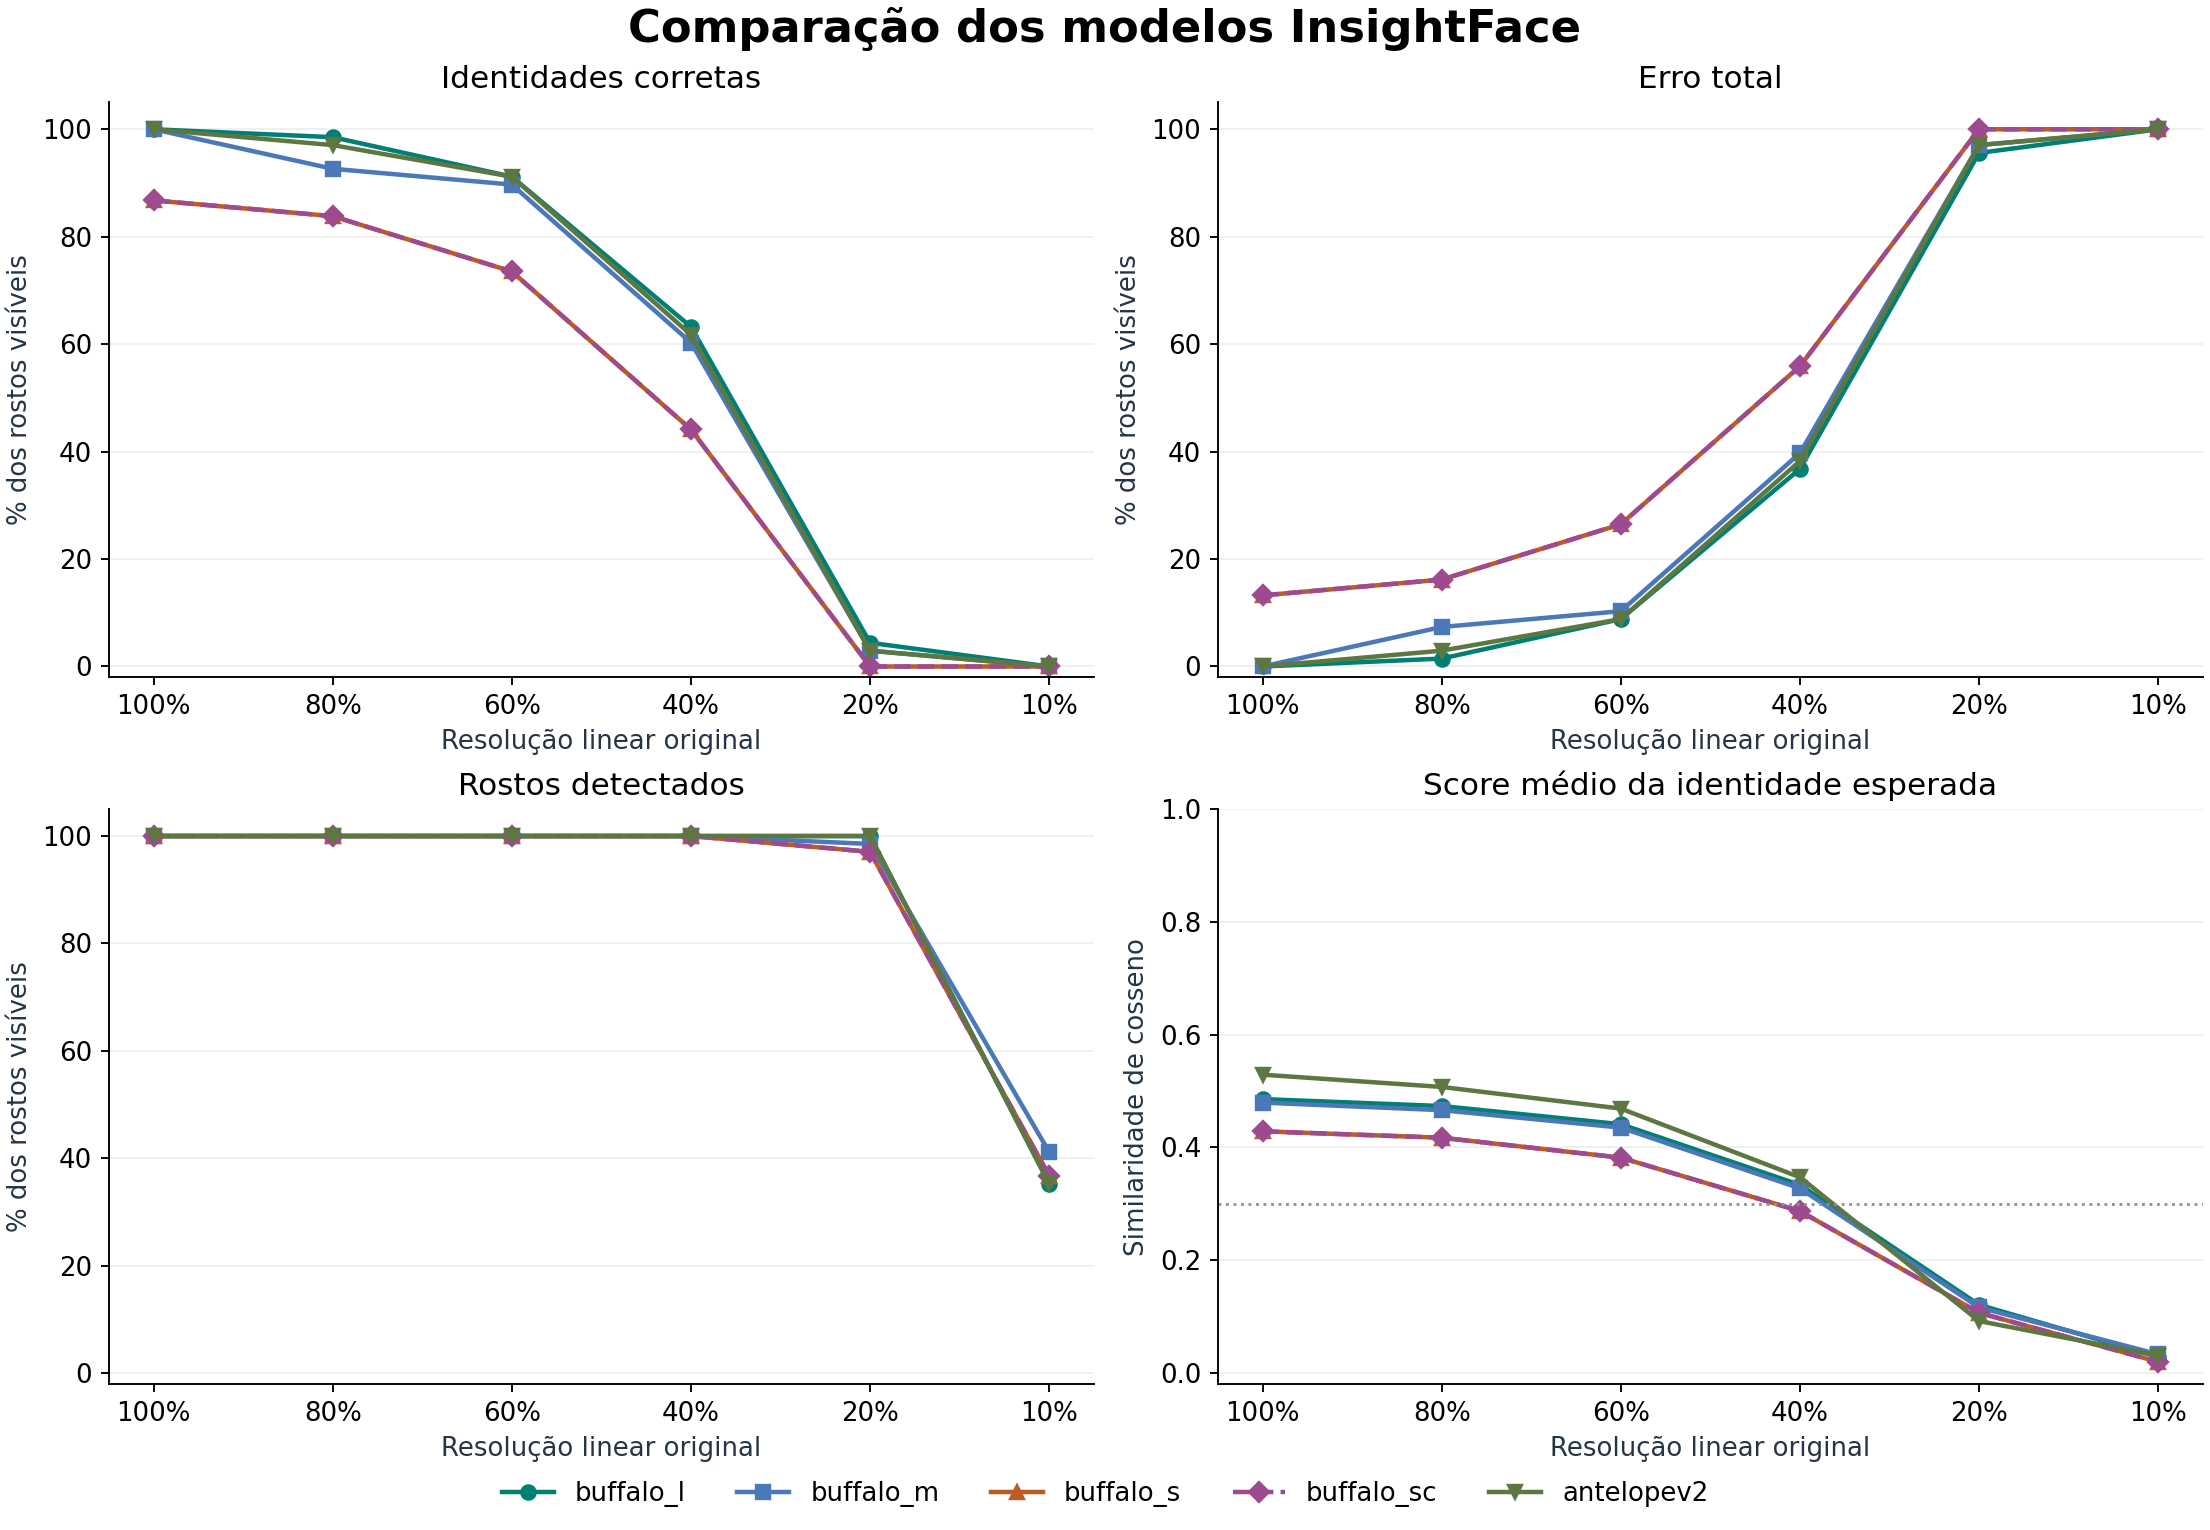

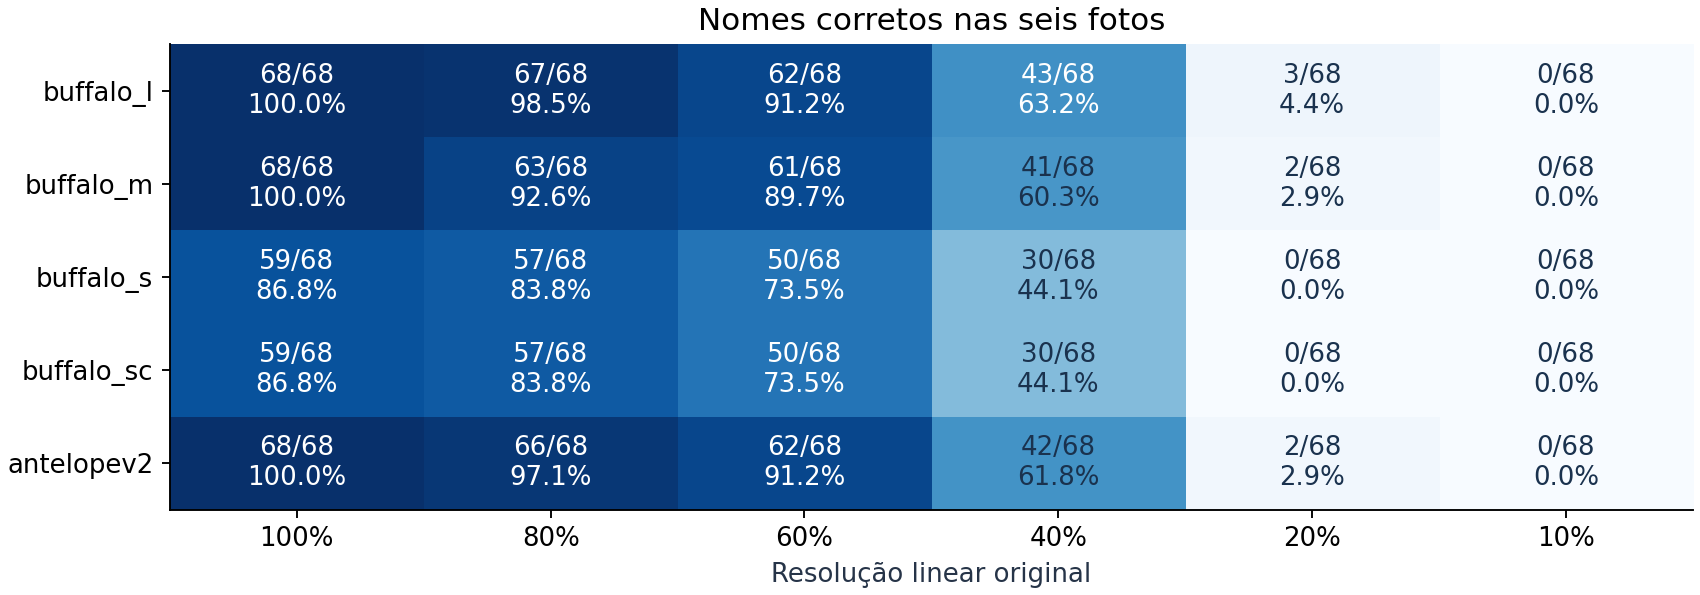

In [10]:
# Exibe os dois gráficos comparativos gerais (painel 2x2 e mapa de calor de acertos) direto na saída do notebook
from IPython.display import Image, display

for nomeGrafico in ("comparacaoModelos.png", "acertosPorModelo.png"):
    caminhoGrafico = pastaExperimento / "graficos" / nomeGrafico
    if caminhoGrafico.is_file():
        display(Image(filename=str(caminhoGrafico)))